# Chapter 2 · Bayesian Inference Methods — Inference Examples

Section 2.2 (pp. 15–21), Figures 1–4.

| Figure | Page | Content |
|---|---|---|
| Figure 1 | p. 16 | Coin likelihood |
| Figure 2 | p. 17 | Coin posteriors |
| Figure 3 | p. 19 | Submarine, 1D (illustration, not generated by code) |
| Figure 4 | p. 21 | Submarine, 2D prior / likelihood / posteriors |

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import lambert_thesis as lt
from lambert_thesis import toy_models, plotting
from lambert_thesis.plotting import savefig

plotting.setup()
rng = lt.set_seed(lt.SEED)   # seed 12345 (no randomness is used in this notebook)

## 2.2.1 Binary coin flipping

A coin flip produces either *heads* ($x=1$) or *tails* ($x=0$). The model has a single parameter $\mu$,
the probability of heads, which gives the Bernoulli distribution

$$\text{Bern}(x\mid\mu)=\mu^x(1-\mu)^{1-x},\qquad x\in\{0,1\}.$$

Interpreted as a function of $\mu$ for an observed result $x_1$, this is the likelihood $p(x_1\mid\mu)$
(Figure 1). Maximum likelihood would pick $\mu=0$ or $\mu=1$ — not helpful for deciding whether the coin is fair.

*Code:* `toy_models.bernoulli(x, mu)` (`src/lambert_thesis/toy_models.py`) is the formula above, evaluated on a grid of 1000 values of $\mu$.

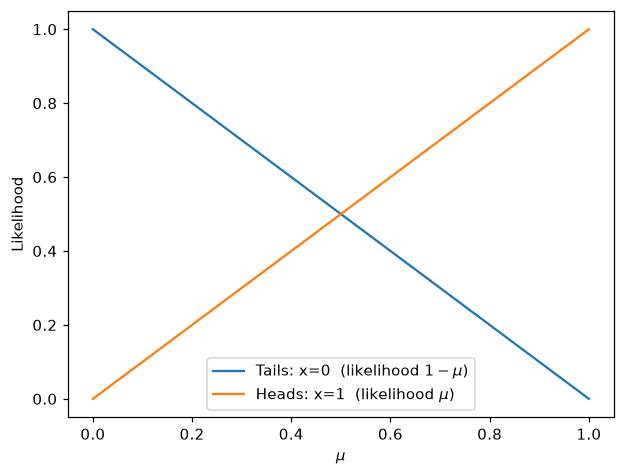

In [2]:
mu = np.linspace(0, 1, 1000)

plt.figure()
plt.plot(mu, toy_models.bernoulli(0, mu), label="Tails: x=0  (likelihood $1-\\mu$)")
plt.plot(mu, toy_models.bernoulli(1, mu), label="Heads: x=1  (likelihood $\\mu$)")
plt.legend()
plt.xlabel(r"$\mu$")
plt.ylabel("Likelihood")
savefig("fig01_coin_likelihood");

**Figure 1 (p. 16).** Likelihood for the coin bias $\mu$; blue and orange are the likelihood functions for tails and heads.

With a uniform prior $\mathcal U(\mu\mid0,1)$, the posterior for $N$ independent throws $D=\{x_1,\dots,x_N\}$ is

$$p(\mu\mid D)=\frac{\prod_{i=1}^N\text{Bern}(x_i\mid\mu)\cdot\mathcal U(\mu\mid0,1)}{p(D)}.$$

Observations can be added one by one or in batches without changing the result. Figure 2 shows the
posterior after an exemplary sequence of throws: the posterior sharpens the more data is added;
a fair coin is not the most probable explanation, but lies within the dominant posterior mass.

*Code:* `toy_models.coin_posterior(flips, mu)` multiplies the likelihoods of all flips on the grid and normalises
numerically with the trapezoidal rule; the normalisation constant $p(D)$ is the integral over the grid.

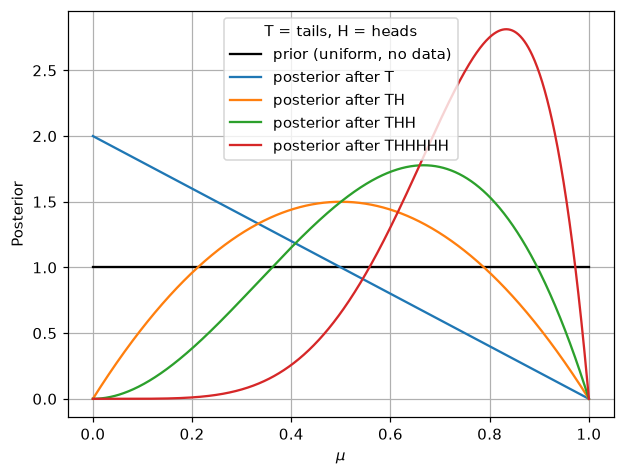

In [3]:
sequences = {
    "T": [0],
    "TH": [0, 1],
    "THH": [0, 1, 1],
    "THHHHH": [0, 1, 1, 1, 1, 1],
}

plt.figure()
plt.plot([0, 1], [1, 1], c="k", label="prior (uniform, no data)")
for seq, flips in sequences.items():
    plt.plot(mu, toy_models.coin_posterior(flips, mu), label=f"posterior after {seq}")
plt.legend(title="T = tails, H = heads")
plt.grid()
plt.xlabel(r"$\mu$")
plt.ylabel("Posterior")
savefig("fig02_coin_posterior");

**Figure 2 (p. 17).** Posterior densities for the coin bias $\mu$ for growing sequences of observations; the prior is shown in black.


For a flat prior the posterior is known analytically: Beta priors lead to Beta posteriors under a Bernoulli likelihood
(the Beta distribution is the *conjugate prior*). In most physical problems no such closed form exists, which is why
numerical methods are needed later.

## 2.2.2 Submarine localization

A submarine of length 10 m is lost at the lateral location $\theta$ and emits air bubbles uniformly along its length.
Assuming bubbles rise straight up, a bubble surfacing at $d_i$ has the likelihood

$$p(d_i\mid\theta)=\begin{cases}\tfrac1{10} & |d_i-\theta|\le5\\0&\text{else,}\end{cases}\qquad
p(D\mid\theta)=\prod_{i=1}^n p(d_i\mid\theta),$$

and the posterior is $p(\theta\mid D)\propto p(D\mid\theta)\,\mathcal U(\theta\mid-c,c)$ for a sufficiently large search range $c$.

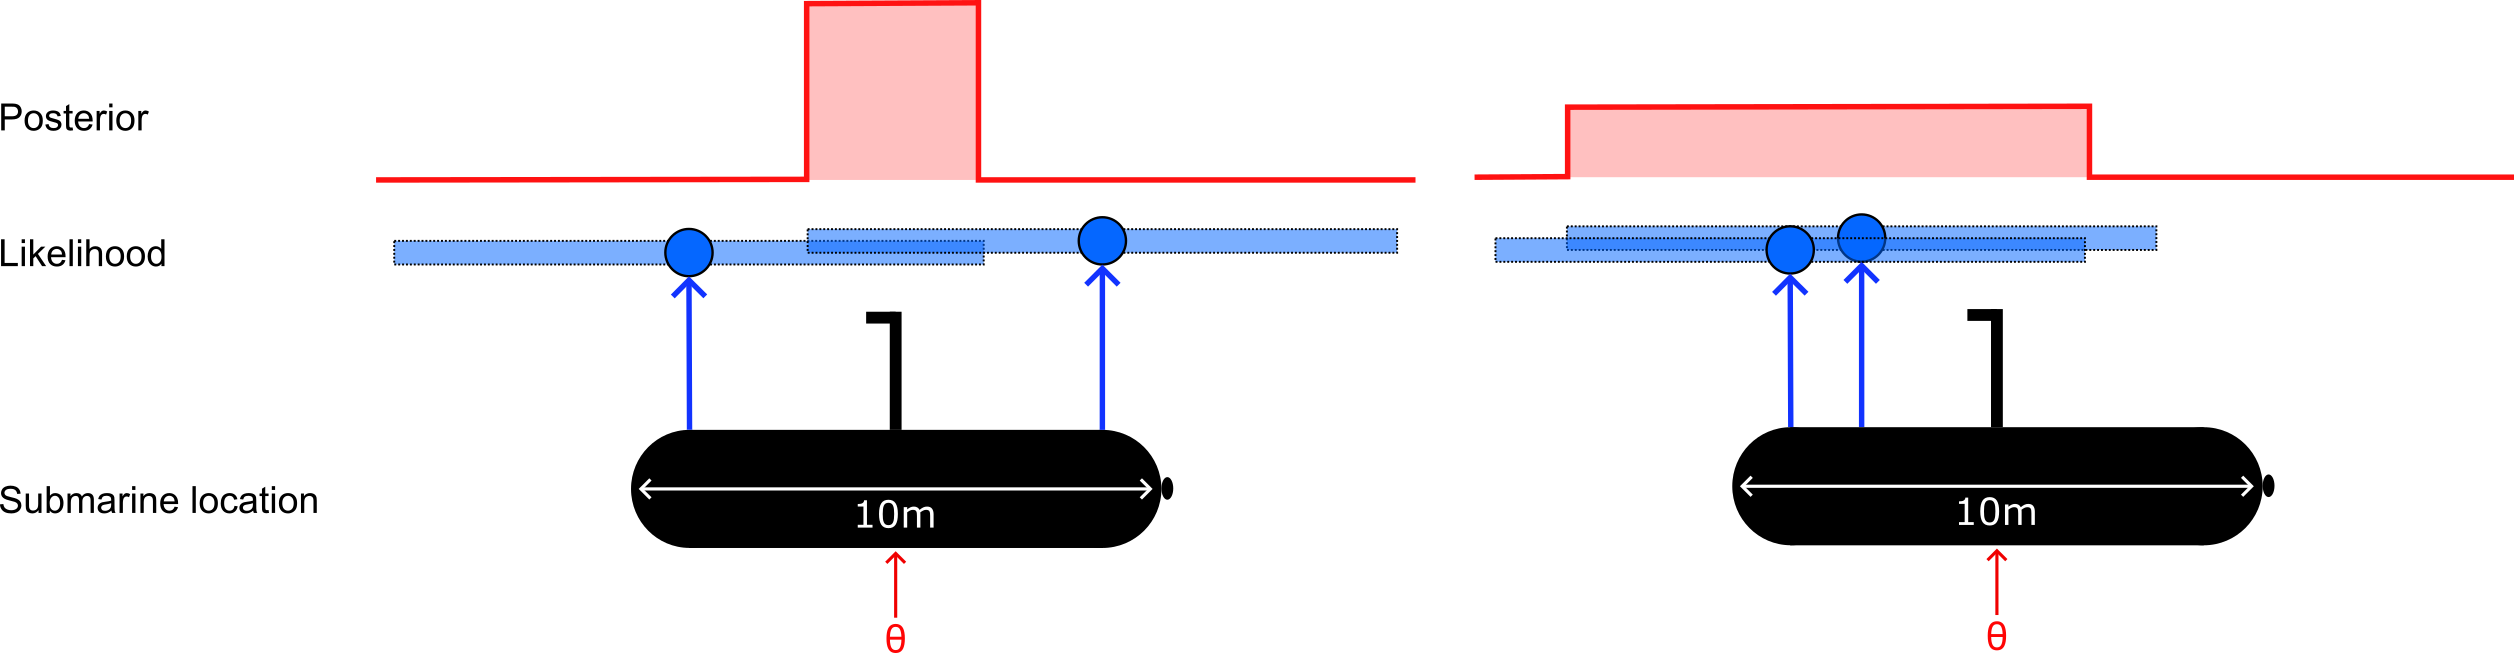

In [4]:
from IPython.display import Image
Image("../assets/fig03_submarine_illustration.png", width=900)

**Figure 3 (p. 19)** (illustration, not computed). Posterior position $\theta$
for two observed bubbles. Left: bubbles far apart → narrow posterior. Right: bubbles close together → wide posterior.

### Adding depth, drift and diffusion

Now the submarine resides at depth $T$, and the bubbles drift with velocity $v$ (ocean current) and diffuse
horizontally with $D^*$, both rescaled by the bubbles' rising speed (so $T$ has units of time).
A box of width 10 convolved with a Gaussian diffusion kernel gives error functions:

$$p(d_i\mid T,\theta)=\tfrac12\left[\operatorname{erf}\left(\frac{5-\theta-d_i+vT}{\sqrt2\,TD^*}\right)
+\operatorname{erf}\left(\frac{5-\theta+d_i+vT}{\sqrt2\,TD^*}\right)\right],
\qquad p(\theta,T\mid D)\propto\prod_i p(d_i\mid\theta,T)\,p(\theta,T).$$

The prior encodes extra knowledge: no radio contact, so the vessel is deeper than $T=10$, and it is not below the
(here sinusoidal) sea floor.

*Code:* `toy_models.bubble_likelihood_2d(d, T, theta, drift, diffusivity)` evaluates the (unnormalised) erf-difference on a
500×500 grid of $(\theta, T)$. The prior is a boolean mask. Everything is plotted with depth pointing down ($-T$).

In [5]:
n = 500
theta_max, depth_max = 50, 70
theta = np.linspace(-theta_max, theta_max, n)
T = np.linspace(depth_max, 0, n)[:-1]               # depth grid (T = 0 excluded: likelihood singular there)
TH, TT = np.meshgrid(theta, T)
extent = [-theta_max, theta_max, -depth_max, 0]

d1, d2 = 15, 40                                     # observed bubble positions at the surface
v = 1.0                                             # drift velocity

sea_floor = 50 + 10 * np.sin(TH / np.pi / 5)        # depth of the sea floor
prior = ((TT < sea_floor) & (TT > 10)).astype(float)

def like(d, D):
    return toy_models.bubble_likelihood_2d(d, TT, TH, drift=v, diffusivity=D)

Parameters: drift $v=1$; diffusion $D^*=0.1$ for the single-bubble posterior and $D^*=0.2$ for the likelihood
sum and the two-bubble posterior.

In [6]:
def ocean_plot(img, title, cmap, bubbles=(d1, d2), show_prior=True):
    """One panel of Figure 4: density on the (theta, -T) plane plus observed bubbles and prior boundary."""
    fig, ax = plt.subplots()
    ax.imshow(img, origin="lower", extent=extent, cmap=cmap, aspect="auto")
    for i, d in enumerate(bubbles):
        ax.axvline(d, c="r", ls="--", label="observed bubbles (surface, $T=0$)" if i == 0 else None)
    if show_prior:
        ax.contour(TH, -TT, prior, levels=[0.5], colors="w", linestyles="--")
        ax.plot([], [], c="w", ls="--", label="prior boundary: min. depth $T=10$ and sea floor")
    ax.set(title=title, xlabel=r"$\theta$", ylabel="T")
    ax.legend(loc="lower right", fontsize=8, facecolor="0.6", framealpha=0.7)
    return fig

### Figure 4 (p. 21), split into its four panels

**Top left — prior.** White = allowed (prior density constant), black = excluded: the vessel is deeper than $T=10$
and above the sinusoidal sea floor.

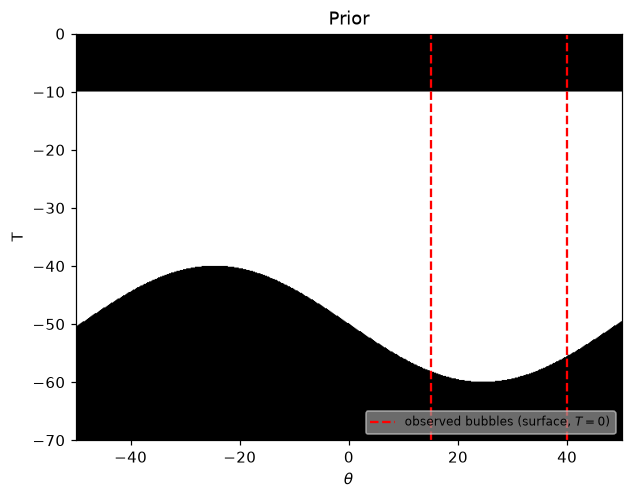

In [7]:
ocean_plot(prior, "Prior", "Greys_r", show_prior=False)
savefig("fig04a_submarine_prior");

**Top right — posterior after a single bubble.** Due to the drift of the bubble with the ocean current, the posterior
is slanted. Its density is highest near the surface and becomes more dilute towards the sea floor.

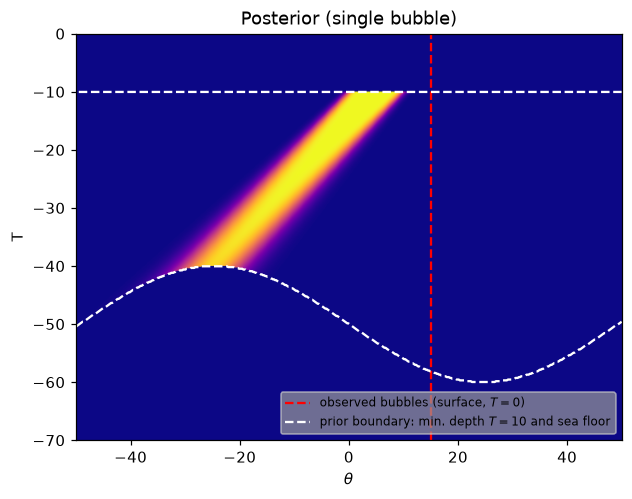

In [8]:
ocean_plot(like(d1, 0.1) * prior, "Posterior (single bubble)", "plasma", bubbles=(d1,))
savefig("fig04b_submarine_posterior_single");

**Bottom left — likelihood.** Shown is the **sum** of the two single-bubble likelihoods instead of the product, so that
the influence of each observation stays visible. Brighter = more likely.

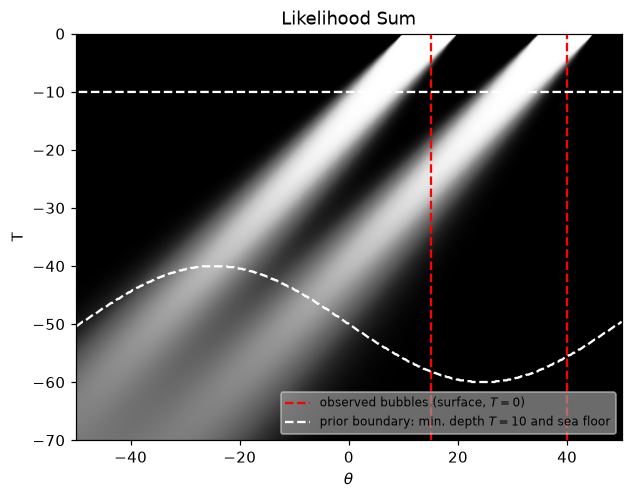

In [9]:
ocean_plot(like(d1, 0.2) + like(d2, 0.2), "Likelihood Sum", "Greys_r")
savefig("fig04c_submarine_likelihood_sum");

**Bottom right — posterior after two bubbles** (product of both likelihoods times the prior). The large distance between
the two bubbles excludes locations near the surface; the vessel most likely hit the sea floor at the elevated point
around $\theta\approx-18$.

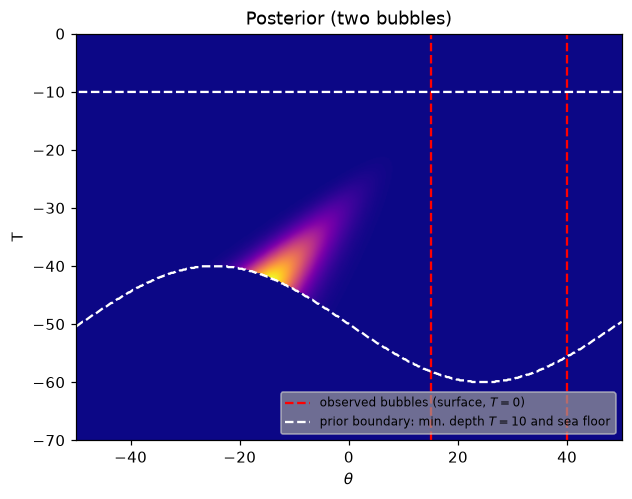

In [10]:
post_two = like(d1, 0.2) * like(d2, 0.2) * prior
ocean_plot(post_two, "Posterior (two bubbles)", "plasma")
savefig("fig04d_submarine_posterior_two");